# Polynomial Neural Sheaf Diffusion

Neural Sheaf Diffusion takes one small step $\mathbf{x} \leftarrow \mathbf{x} - \alpha\,\sigma(\Delta_\mathcal{F}\mathbf{x})$ per layer, so information travels one hop per layer and the model applies the same fixed first-order filter every time. **Polynomial NSD** (PolyNSD; Borgi, Silvestri & Liò, 2025) replaces this step with a learned **spectral filter**: a degree-$K$ Chebyshev polynomial of the sheaf Laplacian. One layer then reaches $K$ hops, and the model can learn *which frequencies* to keep, low ones for homophilic graphs and high ones for heterophilic graphs.

### What You Will Learn
* Why spectral filters on the sheaf Laplacian generalize both GCN-style low-pass filters and NSD's first-order step.
* How Chebyshev polynomials make these filters stable and $K$-hop local, and why the spectrum must be rescaled first.
* The exact PolyNSD update implemented in `src/sheaf_mpnn/nsd/poly_nsd_layers.py`: softmax-normalized Chebyshev weights, a high-pass correction, and a gated residual.
* How to **read a trained PolyNSD**: plot each layer's learned frequency response next to the actual spectrum of its learned sheaf Laplacian, and measure how far its influence reaches through the graph.

### Notebook Roadmap
1. **Motivate** polynomial spectral filtering.
2. **Formalize** Chebyshev filters on sheaf Laplacians and check their locality numerically.
3. **Build** a heterophilic toy graph.
4. **Train** PolyNSD of increasing degree against first-order NSD.
5. **Interpret** the learned spectral responses and the long-range influence.

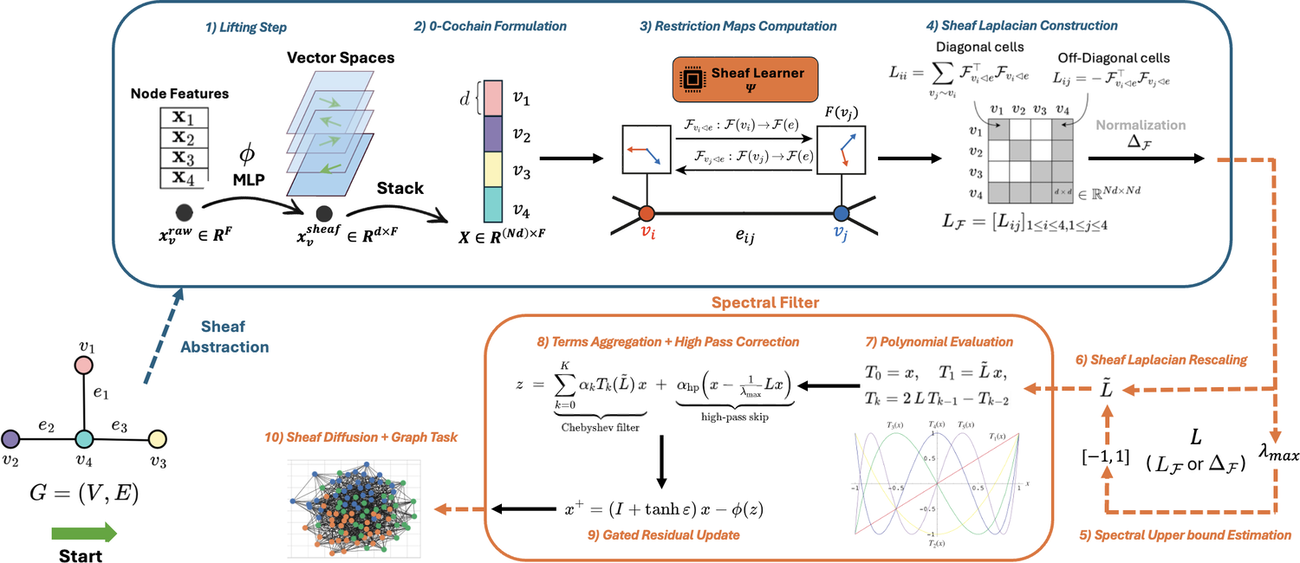

*The PolyNSD architecture. Raw features are lifted to d-dimensional stalks, a sheaf learner predicts the restriction maps, and the sheaf Laplacian is assembled. Its spectral bound lambda_max is used to rescale it to [-1, 1], and a degree-K Chebyshev filter with a high-pass correction and a gated residual produces the next node states.*

<sub>Source: Borgi, Silvestri & Liò (2025), *Polynomial Neural Sheaf Diffusion: A Spectral Filtering Approach on Cellular Sheaves*, [arXiv:2512.00242](https://arxiv.org/abs/2512.00242), Fig. 1. Reproduced for teaching with attribution (CC BY-NC-SA 4.0).</sub>

## Table of Contents

1. [Introduction](#1-introduction)
2. [Environment Setup and Imports](#2-env-setup)
3. [Spectral Filtering on Sheaves](#3-spectral-filtering)
    * [Filters as Polynomials of the Laplacian](#filters-as-polynomials)
    * [The PolyNSD Update](#polynsd-update)
    * [Locality: a Degree-K Filter Sees K Hops](#locality)
4. [Dataset Pipeline: a Heterophilic Graph](#4-dataset-pipeline)
5. [Model Construction](#5-model-construction)
6. [Training Pipeline](#6-training-pipeline)
7. [Interpreting the Learned Filters](#7-interpretation)
    * [Learned Frequency Responses](#frequency-responses)
    * [How Far Does Influence Reach?](#influence)
8. [Configuration, Reproducibility, and Exercises](#8-exercises)

<a id="1-introduction"></a>
# 1. Introduction

Notebook 0 showed that a GCN layer multiplies graph frequency $\lambda$ by $(1 - \lambda)$, a fixed **low-pass** filter. Notebook 1 replaced the graph Laplacian with a learned **sheaf** Laplacian $\Delta_\mathcal{F}$, but kept a fixed first-order update. Two limitations remain:
1. **Fixed shape.** A first-order step can only apply one simple response; it cannot, for instance, keep low *and* high frequencies while suppressing the middle.
2. **One hop per layer.** Reaching $K$ hops costs $K$ layers, and every layer adds parameters, nonlinearities, and more smoothing.

A polynomial filter $p_\theta(\Delta_\mathcal{F}) = \sum_{k=0}^{K} \theta_k\, \Delta_\mathcal{F}^k$ addresses both: its shape is learned through $\theta$, and it touches exactly the $K$-hop neighbourhood, because $(\Delta_\mathcal{F}^k)_{uv} = 0$ whenever $u$ and $v$ are more than $k$ hops apart. Because $\Delta_\mathcal{F}$ is a *sheaf* Laplacian, the frequencies themselves are adapted to the data: a "low frequency" is a signal that agrees across edges **after transport by the restriction maps**, not a signal that is merely constant.

<a id="2-env-setup"></a>
# 2. Environment Setup and Imports

Use the repository's Python 3.13 environment (`uv sync`) and run the notebook top to bottom from a fresh kernel. Everything runs on CPU in one to two minutes.

In [1]:
# =====================================================================
# 1. Standard Library & Repository Path
# =====================================================================
import copy
import random
import sys
import warnings
from pathlib import Path


def find_repo_root(start: Path | None = None) -> Path:
    """Find the repository root (the folder holding pyproject.toml and src/)."""
    start = (start or Path.cwd()).resolve()
    for p in [start, *start.parents]:
        if (p / "pyproject.toml").exists() and (p / "src").exists():
            return p
    raise FileNotFoundError("Could not locate the repository")


REPO_ROOT = find_repo_root()
SRC_PATH = REPO_ROOT / "src"
if str(SRC_PATH) not in sys.path:
    sys.path.insert(0, str(SRC_PATH))

# =====================================================================
# 2. Core Scientific Libraries
# =====================================================================
import matplotlib.pyplot as plt
import numpy as np
import torch
import torch.nn.functional as F
from torch_geometric.data import Data

# =====================================================================
# 3. Reproducibility
# =====================================================================
warnings.filterwarnings("ignore")
SEED = 42


def set_seed(seed: int) -> None:
    random.seed(seed)
    np.random.seed(seed)  # noqa: NPY002
    torch.manual_seed(seed)


set_seed(SEED)
torch.set_num_threads(1)  # small graphs: avoid thread overhead and nondeterminism

print("--- Environment Status ---")
print(f"Repository root: {REPO_ROOT}")
print(f"Python:  {sys.version.split()[0]}")
print(f"PyTorch: {torch.__version__}")

# =====================================================================
# 4. Repository-Specific Modules
# =====================================================================
import networkx as nx
from torch_geometric.utils import homophily, stochastic_blockmodel_graph

from sheaf_mpnn.nsd import NSDModel, NSDVariant
from sheaf_mpnn.nsd.poly_nsd_model import PolyNSDModel, PolyNSDVariant

print("Loaded PolyNSDModel and the first-order NSDModel baseline.")

--- Environment Status ---
Repository root: <repo>
Python:  3.13.12
PyTorch: 2.8.0
Loaded PolyNSDModel and the first-order NSDModel baseline.


<a id="3-spectral-filtering"></a>
# 3. Spectral Filtering on Sheaves

<a id="filters-as-polynomials"></a>
### 3.1 Filters as Polynomials of the Laplacian

Write the normalized sheaf Laplacian as $\Delta_\mathcal{F} = U \Lambda U^{\top}$ with eigenvalues $0 \le \lambda_i \le \lambda_{\max}$. A **spectral filter** rescales each eigencomponent: $g(\Delta_\mathcal{F})\,\mathbf{x} = U g(\Lambda) U^{\top}\mathbf{x}$. Computing $U$ is prohibitively expensive for large graphs, but a polynomial filter never needs it, because $p(\Delta_\mathcal{F})\,\mathbf{x}$ is just $K$ repeated applications of $\Delta_\mathcal{F}$, i.e. $K$ rounds of message passing.

Monomials $\lambda^k$ are numerically poor (they grow or vanish quickly). **Chebyshev polynomials** are the standard fix. On the rescaled operator $\tilde{\Delta}_\mathcal{F} = \tfrac{2}{\lambda_{\max}}\Delta_\mathcal{F} - I$, whose spectrum lies in $[-1, 1]$, they satisfy

$$T_0(\tilde\Delta)\mathbf{z} = \mathbf{z}, \qquad T_1(\tilde\Delta)\mathbf{z} = \tilde\Delta\mathbf{z}, \qquad T_k(\tilde\Delta)\mathbf{z} = 2\tilde\Delta\, T_{k-1}(\tilde\Delta)\mathbf{z} - T_{k-2}(\tilde\Delta)\mathbf{z},$$

and every $T_k$ is bounded by $1$ in absolute value on $[-1, 1]$. The rescaling is essential: outside $[-1, 1]$ the polynomials explode. For the symmetrically normalized sheaf Laplacian, $\lambda_{\max} = 2$ is a valid bound, which is the repository default.

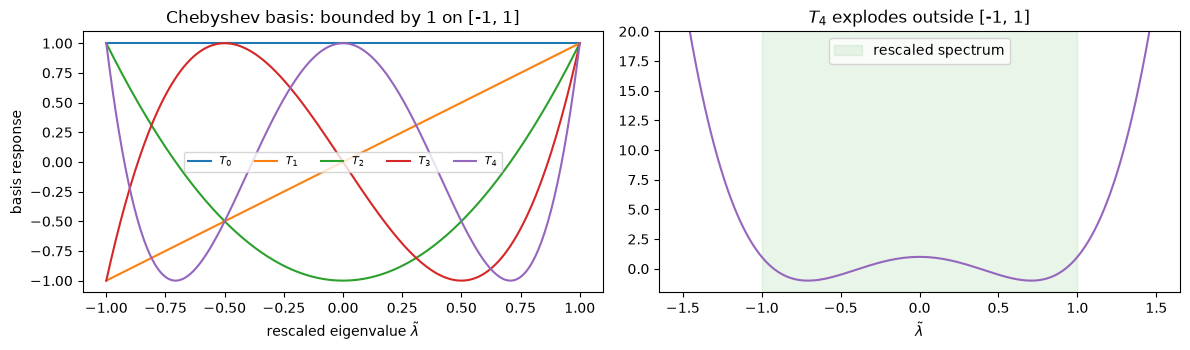

In [2]:
# =====================================================================
# The Chebyshev basis on [-1, 1]
# =====================================================================
grid = np.linspace(-1, 1, 300)
fig, axes = plt.subplots(1, 2, figsize=(12, 3.6))
for k in range(5):
    coeff = np.zeros(k + 1)
    coeff[-1] = 1
    axes[0].plot(grid, np.polynomial.chebyshev.chebval(grid, coeff), label=f"$T_{k}$")
axes[0].set(
    xlabel=r"rescaled eigenvalue $\tilde\lambda$",
    ylabel="basis response",
    title="Chebyshev basis: bounded by 1 on [-1, 1]",
)
axes[0].legend(ncol=5, fontsize=8)

wide = np.linspace(-1.5, 1.5, 300)
coeff = np.zeros(5)
coeff[-1] = 1
axes[1].plot(wide, np.polynomial.chebyshev.chebval(wide, coeff), color="tab:purple")
axes[1].axvspan(-1, 1, color="tab:green", alpha=0.1, label="rescaled spectrum")
axes[1].set(
    xlabel=r"$\tilde\lambda$", title="$T_4$ explodes outside [-1, 1]", ylim=(-2, 20)
)
axes[1].legend()
plt.tight_layout()
plt.show()

<a id="polynsd-update"></a>
### 3.2 The PolyNSD Update

Each PolyNSD layer (`BasePolyNSDConv.forward`) performs these steps on the lifted stalks $\mathbf{x} \in \mathbb{R}^{N \times d \times f}$:
1. **Stalk transform:** $\mathbf{z} = W_1\mathbf{x}W_2$, as in NSD.
2. **Maps and Laplacian:** predict the restriction maps once, normalize them, and keep them **fixed for all $K$ steps** of the recurrence. They can change from one layer to the next.
3. **Chebyshev filter** with **softmax-normalized** weights $\boldsymbol{\theta} = \operatorname{softmax}(\boldsymbol{\theta}_{\text{raw}})$, a convex combination, so $|p_\theta| \le 1$ on the spectrum:
   $$\mathbf{p} = \sum_{k=0}^{K} \theta_k\, T_k(\tilde\Delta_\mathcal{F})\,\mathbf{z}.$$
4. **High-pass correction** with a learnable scalar $\alpha_{\text{hp}}$ (initialized at 0): $\mathbf{p} \leftarrow \mathbf{p} + \alpha_{\text{hp}}\big(\mathbf{z} - \Delta_\mathcal{F}\mathbf{z}/\lambda_{\max}\big)$.
5. **Gated residual:** $\mathbf{x}^{+} = (1 + \tanh\boldsymbol{\varepsilon}) \odot \mathbf{x} - \sigma(\mathbf{p})$, with a learnable per-stalk gate $\boldsymbol{\varepsilon}$ (initialized at 0).

Before the activation, the layer therefore applies the frequency response

$$m(\lambda) = \sum_{k=0}^{K} \theta_k\, T_k\!\Big(\tfrac{2\lambda}{\lambda_{\max}} - 1\Big) + \alpha_{\text{hp}}\Big(1 - \tfrac{\lambda}{\lambda_{\max}}\Big),$$

which is what we plot in Section 7. At initialization $\boldsymbol{\theta}_{\text{raw}} = 0$, so all $\theta_k = 1/(K+1)$ and the filter is a plain average of the Chebyshev basis.

<a id="locality"></a>
### 3.3 Locality: a Degree-K Filter Sees K Hops

To see the locality concretely, we apply $T_k(\tilde\Delta)$ to an **impulse** (a signal that is 1 on a single node and 0 elsewhere) on a ring, using the trivial sheaf for clarity. The response of $T_k$ is **zero beyond $k$ hops**. On this regular ring, it even skips every other distance: $\tilde\Delta = -D^{-1/2}AD^{-1/2}$ here, and $T_k$ has the parity of $k$, so only distances $k, k-2, \dots$ are reached.

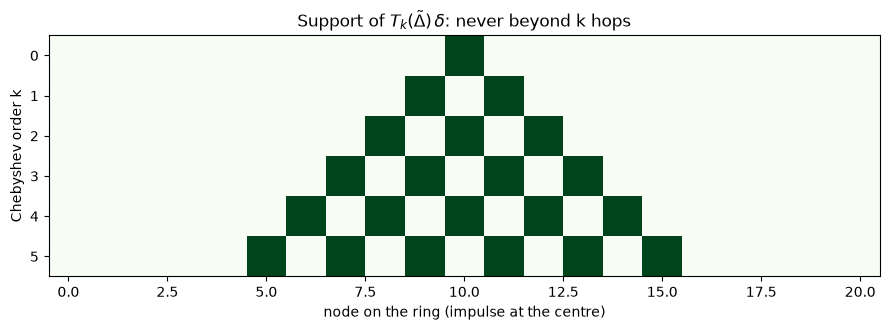

T_0: non-zero on 1 nodes, furthest at 0 hops
T_1: non-zero on 2 nodes, furthest at 1 hops
T_2: non-zero on 3 nodes, furthest at 2 hops
T_3: non-zero on 4 nodes, furthest at 3 hops
T_4: non-zero on 5 nodes, furthest at 4 hops
T_5: non-zero on 6 nodes, furthest at 5 hops


In [3]:
# =====================================================================
# Impulse responses of the Chebyshev terms on a ring (trivial sheaf)
# =====================================================================
n_ring = 21
A_ring = torch.zeros(n_ring, n_ring)
for u in range(n_ring):
    A_ring[u, (u + 1) % n_ring] = A_ring[(u + 1) % n_ring, u] = 1
d_inv_sqrt = A_ring.sum(1).pow(-0.5)
Delta_ring = torch.eye(n_ring) - d_inv_sqrt[:, None] * A_ring * d_inv_sqrt[None, :]
L_tilde = Delta_ring - torch.eye(
    n_ring
)  # (2 / lambda_max) * Delta - I with lambda_max = 2

impulse = torch.zeros(n_ring)
impulse[n_ring // 2] = 1.0
T_prev, T_curr = impulse, L_tilde @ impulse
responses = [T_prev, T_curr]
for _ in range(2, 6):
    T_prev, T_curr = T_curr, 2 * L_tilde @ T_curr - T_prev
    responses.append(T_curr)

fig, ax = plt.subplots(figsize=(9, 3.4))
im = ax.imshow(
    torch.stack(responses).abs().numpy() > 1e-9, aspect="auto", cmap="Greens"
)
ax.set(
    xlabel="node on the ring (impulse at the centre)",
    ylabel="Chebyshev order k",
    title="Support of $T_k(\\tilde\\Delta)\\,\\delta$: never beyond k hops",
)
plt.tight_layout()
plt.show()
for k, r in enumerate(responses):
    support = (r.abs() > 1e-9).nonzero().flatten()
    print(
        f"T_{k}: non-zero on {len(support)} nodes, furthest at {int((support - n_ring // 2).abs().max())} hops"
    )

<a id="4-dataset-pipeline"></a>
# 4. Dataset Pipeline: a Heterophilic Graph

We sample a two-class **stochastic block model** with 160 nodes, average degree 6, and edge homophily around 0.15: most edges join *different* classes. Each node has 4 features, of which only the first carries a weak class signal. This is the regime where a low-pass filter (GCN, or NSD with near-identity maps) mixes the classes, and where a learned filter should favour **high** frequencies.

In [4]:
def random_splits(n: int, train: float = 0.4, val: float = 0.2, seed: int = SEED):
    """Disjoint boolean train/val/test masks over n nodes."""
    g = torch.Generator().manual_seed(seed)
    perm = torch.randperm(n, generator=g)
    n_train, n_val = int(train * n), int(val * n)
    masks = [torch.zeros(n, dtype=torch.bool) for _ in range(3)]
    masks[0][perm[:n_train]] = True
    masks[1][perm[n_train : n_train + n_val]] = True
    masks[2][perm[n_train + n_val :]] = True
    return masks


# =====================================================================
# Heterophilic stochastic block model
# =====================================================================
set_seed(SEED)
n, h, avg_degree = 160, 0.15, 6
half = n // 2
p_in, p_out = h * avg_degree / half, (1 - h) * avg_degree / half
edge_index = stochastic_blockmodel_graph([half, half], [[p_in, p_out], [p_out, p_in]])
y = torch.cat([torch.zeros(half), torch.ones(half)]).long()
x = torch.randn(n, 4)
x[:, 0] += 0.7 * (2 * y.float() - 1)
train_mask, val_mask, test_mask = random_splits(n)
data = Data(
    x=x,
    y=y,
    edge_index=edge_index,
    train_mask=train_mask,
    val_mask=val_mask,
    test_mask=test_mask,
)

G = nx.Graph()
G.add_nodes_from(range(n))
G.add_edges_from(edge_index.t().tolist())
print("--- Heterophilic toy graph ---")
print(data)
print(f"Edge homophily: {homophily(edge_index, y, method='edge'):.3f}")
print(
    f"Connected components: {nx.number_connected_components(G)} | diameter of the largest: "
    f"{nx.diameter(G.subgraph(max(nx.connected_components(G), key=len)))}"
)

--- Heterophilic toy graph ---
Data(x=[160, 4], edge_index=[2, 930], y=[160], train_mask=[160], val_mask=[160], test_mask=[160])
Edge homophily: 0.157
Connected components: 2 | diameter of the largest: 5


<a id="5-model-construction"></a>
# 5. Model Construction

We compare, with diagonal maps ($d = 2$) and two layers each:
* first-order **NSD** (one hop per layer, fixed update);
* **PolyNSD** with degree $K \in \{1, 2, 4\}$.

With two layers, NSD and PolyNSD-$K{=}1$ see 2 hops, while PolyNSD-$K{=}4$ sees 8 hops.

In [5]:
# =====================================================================
# Model factories
# =====================================================================
def poly_model(degree):
    return PolyNSDModel(
        4,
        2,
        stalk_dim=2,
        hidden_dim=8,
        num_layers=2,
        variant=PolyNSDVariant.DIAGONAL,
        degree=degree,
        lambda_max=2.0,
    )


def nsd_model():
    return NSDModel(
        4, 2, stalk_dim=2, hidden_dim=8, num_layers=2, variant=NSDVariant.DIAGONAL
    )


demo = poly_model(4)
layer0 = demo.layers[0]
print(f"Layer type: {type(layer0).__name__}")
print(f"degree K = {layer0.degree}, lambda_max = {layer0.lambda_max}")
print(
    f"theta_raw = {layer0.theta_raw.data.tolist()}  -> softmax weights "
    f"{torch.softmax(layer0.theta_raw, 0).tolist()}"
)
print(f"hp_alpha = {float(layer0.hp_alpha):.2f}, gate eps = {layer0.eps.data.tolist()}")

Layer type: DiagonalPolyNSDConv
degree K = 4, lambda_max = 2.0
theta_raw = [0.0, 0.0, 0.0, 0.0, 0.0]  -> softmax weights [0.20000000298023224, 0.20000000298023224, 0.20000000298023224, 0.20000000298023224, 0.20000000298023224]
hp_alpha = 0.00, gate eps = [0.0, 0.0]


<a id="6-training-pipeline"></a>
# 6. Training Pipeline

Each model is trained with three seeds (masked cross-entropy, validation-based selection). We also time the training, since the cost grows linearly with $K$.

--- Test accuracy (3 seeds) ---
NSD          0.812 +/- 0.046   (0.4s per run)
PolyNSD K=1  0.901 +/- 0.019   (0.5s per run)
PolyNSD K=2  0.854 +/- 0.096   (0.5s per run)
PolyNSD K=4  0.760 +/- 0.048   (0.7s per run)


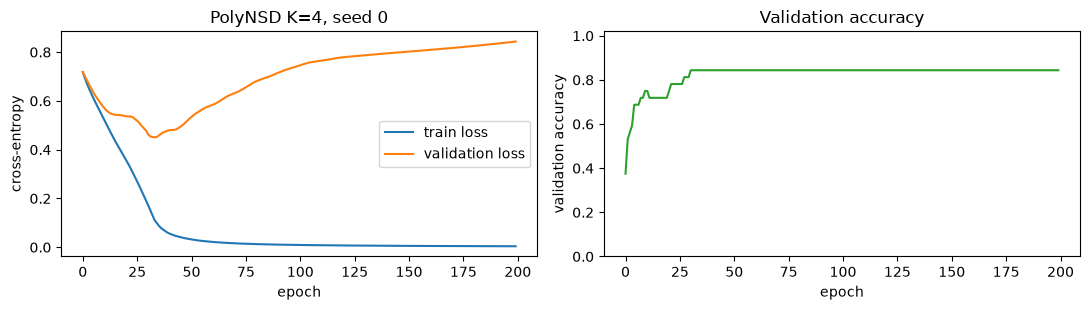

In [6]:
# =====================================================================
# Masked training with validation-based model selection
# =====================================================================
def accuracy(logits: torch.Tensor, y: torch.Tensor, mask: torch.Tensor) -> float:
    return (logits[mask].argmax(-1) == y[mask]).float().mean().item()


def train_model(
    model, predict, data, epochs=150, lr=0.01, weight_decay=5e-4, extra_loss=None
):
    """Adam on masked cross-entropy; restores the state with the lowest validation loss.

    Args:
        model: the network to optimize.
        predict: zero-argument callable returning logits [N, C] for the whole graph.
        data: PyG Data with y, train_mask, val_mask, test_mask.
        epochs: number of full-batch optimization steps.
        lr: Adam learning rate.
        weight_decay: Adam L2 penalty.
        extra_loss: optional callable(epoch) -> scalar added to the loss (e.g. a KL term).

    Returns:
        (history, test_accuracy) where history holds one dict per epoch.
    """
    optimizer = torch.optim.Adam(model.parameters(), lr=lr, weight_decay=weight_decay)
    history, best_val, best_state = [], float("inf"), None
    for epoch in range(epochs):
        model.train()
        optimizer.zero_grad()
        logits = predict()
        loss = F.cross_entropy(logits[data.train_mask], data.y[data.train_mask])
        if extra_loss is not None:
            loss = loss + extra_loss(epoch)
        assert torch.isfinite(loss), "non-finite training loss"
        loss.backward()
        optimizer.step()

        model.eval()
        with torch.no_grad():
            val_logits = predict()
            val_loss = F.cross_entropy(
                val_logits[data.val_mask], data.y[data.val_mask]
            ).item()
        history.append(
            {
                "train_loss": loss.item(),
                "val_loss": val_loss,
                "val_acc": accuracy(val_logits, data.y, data.val_mask),
            }
        )
        if val_loss < best_val:
            best_val, best_state = val_loss, copy.deepcopy(model.state_dict())

    model.load_state_dict(best_state)
    model.eval()
    with torch.no_grad():
        test_acc = accuracy(predict(), data.y, data.test_mask)
    return history, test_acc


def plot_history(history, title):
    """Training/validation curves of one run."""
    fig, axes = plt.subplots(1, 2, figsize=(11, 3.2))
    axes[0].plot([h["train_loss"] for h in history], label="train loss")
    axes[0].plot([h["val_loss"] for h in history], label="validation loss")
    axes[0].set(xlabel="epoch", ylabel="cross-entropy", title=title)
    axes[0].legend()
    axes[1].plot([h["val_acc"] for h in history], color="tab:green")
    axes[1].set(
        xlabel="epoch",
        ylabel="validation accuracy",
        ylim=(0, 1.02),
        title="Validation accuracy",
    )
    plt.tight_layout()
    plt.show()


# =====================================================================
# Train NSD and PolyNSD of increasing degree
# =====================================================================
import time

configs = {
    "NSD": nsd_model,
    "PolyNSD K=1": lambda: poly_model(1),
    "PolyNSD K=2": lambda: poly_model(2),
    "PolyNSD K=4": lambda: poly_model(4),
}
results, trained = {}, {}
for name, factory in configs.items():
    accs, t0 = [], time.time()
    for seed in (0, 1, 2):
        set_seed(seed)
        model = factory()
        history, acc = train_model(
            model, lambda m=model: m(data.x, data.edge_index), data, epochs=200
        )
        accs.append(acc)
        if seed == 0:
            trained[name] = (model, history)
    results[name] = (accs, (time.time() - t0) / 3)

print("--- Test accuracy (3 seeds) ---")
for name, (accs, secs) in results.items():
    print(
        f"{name:<12} {np.mean(accs):.3f} +/- {np.std(accs):.3f}   ({secs:.1f}s per run)"
    )
plot_history(trained["PolyNSD K=4"][1], "PolyNSD K=4, seed 0")

**Reading the table.** A higher degree is *not* automatically better. This graph is small: its largest component has a diameter of about 5, so two layers of even a first-order model already cover most of it, and the extra flexibility of a degree-4 filter can overfit 64 training nodes. Degree pays off when information has to travel far (Section 7.2) or when the spectrum needs a sharper filter than a first-order step can express. On real benchmarks, the paper selects $K$ per dataset (see the exercise on the degree sweep). The interpretation below uses the $K = 4$ model because its richer filter is the most instructive to read.

<a id="7-interpretation"></a>
# 7. Interpreting the Learned Filters

<a id="frequency-responses"></a>
### 7.1 Learned Frequency Responses

Every PolyNSD layer stores its filter in two parameters, `theta_raw` and `hp_alpha`, so we can plot the response $m(\lambda)$ of Section 3.2 directly. A response is only meaningful where the operator actually has eigenvalues, though. We therefore also **reconstruct each layer's learned sheaf Laplacian** from its restriction maps, using forward hooks to capture the layer inputs, and mark its eigenvalues under the curve.

For diagonal maps, the $d$ stalk channels decouple, so the operator is a stack of $d$ ordinary $N \times N$ matrices with entries
$(\Delta)_{vv} = \sum_{e \ni v} \hat{s}_e$ and $(\Delta)_{vu} = -\hat{c}_e$, where $\hat{s}_e$ and $\hat{c}_e$ are the normalized self- and cross-map products returned by the layer's `_apply_norm`.

layer 0: theta = [0.205 0.203 0.142 0.143 0.306], hp_alpha = +0.004, spectrum in [-0.00, 1.07]
layer 1: theta = [0.143 0.266 0.173 0.142 0.277], hp_alpha = -0.313, spectrum in [-0.00, 1.31]


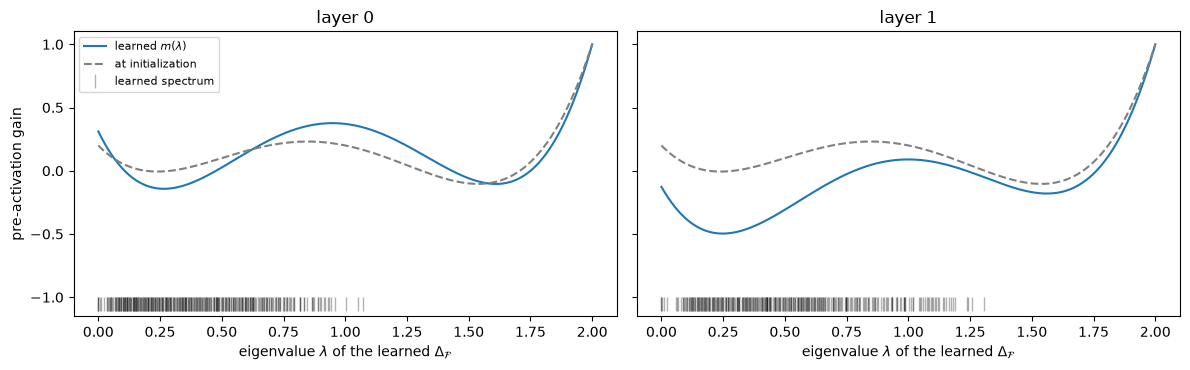

In [7]:
# =====================================================================
# Capture each layer's inputs, rebuild its sheaf Laplacian, plot m(lambda)
# =====================================================================
def capture_layer_inputs(model):
    inputs = []
    hooks = [
        layer.register_forward_pre_hook(lambda mod, args: inputs.append(args))
        for layer in model.layers
    ]
    with torch.no_grad():
        model(data.x, data.edge_index)
    for hk in hooks:
        hk.remove()
    return inputs


def diagonal_sheaf_spectrum(layer, x_feat, edge_index):
    """Eigenvalues of the layer's normalized diagonal sheaf Laplacian (all stalk channels)."""
    with torch.no_grad():
        self_map, cross_map = layer.get_map_products(x_feat, edge_index)
        norm_self, norm_cross = layer._apply_norm(
            self_map, cross_map, edge_index, x_feat.size(0)
        )
    src_i, dst_i = edge_index
    eigs = []
    for k in range(norm_self.size(1)):
        M = torch.zeros(x_feat.size(0), x_feat.size(0))
        M.index_put_((dst_i, dst_i), norm_self[:, k], accumulate=True)
        M.index_put_((dst_i, src_i), -norm_cross[:, k], accumulate=True)
        eigs.append(torch.linalg.eigvalsh((M + M.T) / 2))
    return torch.cat(eigs).numpy()


def response(layer, lam):
    theta = torch.softmax(layer.theta_raw.detach(), 0).numpy()
    rescaled = 2 * lam / layer.lambda_max - 1
    poly = np.polynomial.chebyshev.chebval(rescaled, theta)
    return poly + float(layer.hp_alpha) * (1 - lam / layer.lambda_max)


model = trained["PolyNSD K=4"][0]
inputs = capture_layer_inputs(model)
lam = np.linspace(0, 2, 300)
fig, axes = plt.subplots(1, len(model.layers), figsize=(12, 3.8), sharey=True)
for i, (ax, layer) in enumerate(zip(axes, model.layers, strict=True)):
    x_feat, _, ei = inputs[i]
    eig = diagonal_sheaf_spectrum(layer, x_feat, ei)
    ax.plot(lam, response(layer, lam), label="learned $m(\\lambda)$")
    ax.plot(
        lam,
        response(poly_model(4).layers[0], lam),
        ls="--",
        color="gray",
        label="at initialization",
    )
    ax.plot(
        eig,
        np.full_like(eig, -1.05),
        "|",
        color="k",
        alpha=0.3,
        ms=10,
        label="learned spectrum",
    )
    ax.set(
        title=f"layer {i}",
        xlabel="eigenvalue $\\lambda$ of the learned $\\Delta_\\mathcal{F}$",
    )
    print(
        f"layer {i}: theta = {np.round(torch.softmax(layer.theta_raw.detach(), 0).numpy(), 3)}, "
        f"hp_alpha = {float(layer.hp_alpha):+.3f}, spectrum in [{eig.min():.2f}, {eig.max():.2f}]"
    )
axes[0].set_ylabel("pre-activation gain")
axes[0].legend(fontsize=8)
plt.tight_layout()
plt.show()

**How to read the plot.** The dashed curve is the untrained filter, and the solid curve is what training made of it. Compare the gain at small $\lambda$ (components that agree across edges *after transport*) with the gain at large $\lambda$ (components that disagree). The marks along the bottom show where the learned operator actually has eigenvalues: the filter shape only matters there. Two cautions:
* the response acts on $\mathbf{z} = W_1\mathbf{x}W_2$ and is followed by $\sigma$ and the gated residual $\mathbf{x}^{+} = (1+\tanh\varepsilon)\mathbf{x} - \sigma(\mathbf{p})$. A *positive* gain therefore **removes** that component from the state, while a negative gain amplifies it;
* the spectrum is itself learned: the restriction maps decide which signals count as "low frequency". The filter and the sheaf are trained together and should be read together.

The paper reports the same kind of plot on real datasets, separating the polynomial part from the high-pass term:

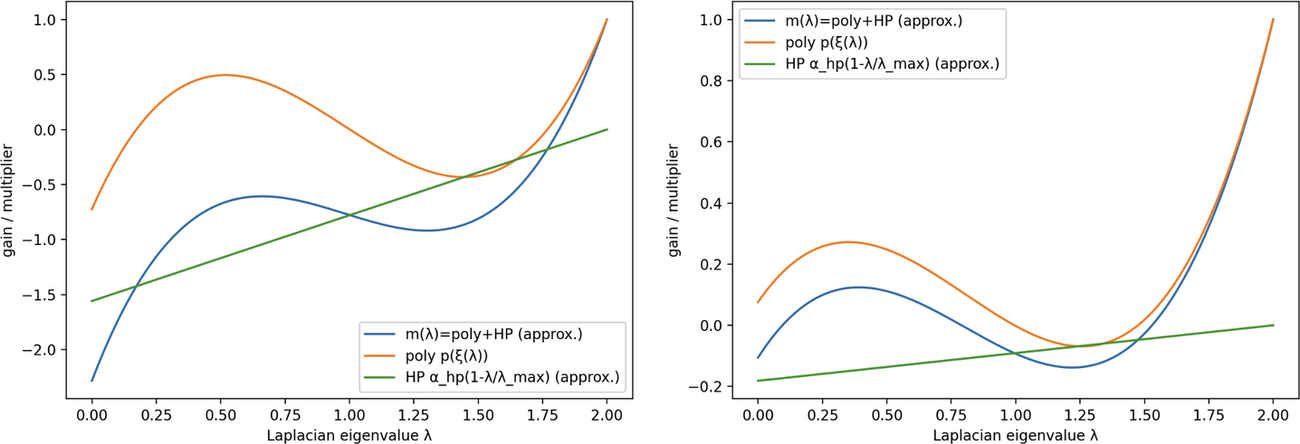

*Representative learned spectral responses on PubMed (homophilic, left) and Chameleon (heterophilic, right): the combined response m(lambda), the Chebyshev polynomial part, and the high-pass correction term, as functions of the sheaf Laplacian eigenvalue.*

<sub>Source: Borgi, Silvestri & Liò (2025), *Polynomial Neural Sheaf Diffusion: A Spectral Filtering Approach on Cellular Sheaves*, [arXiv:2512.00242](https://arxiv.org/abs/2512.00242), appendix. Reproduced for teaching with attribution (CC BY-NC-SA 4.0).</sub>

<a id="influence"></a>
### 7.2 How Far Does Influence Reach?

A degree-$K$ layer can only *connect* nodes within $K$ hops, but whether it actually *uses* distant nodes is an empirical question. We measure the **influence** of node $v$ on node $u$ as the size of the Jacobian $\big\|\partial\, \text{logits}_u / \partial \mathbf{x}_v\big\|_1$, average it over target nodes and group it by hop distance, then normalize by the influence of the node on itself. This is the diagnostic behind the paper's over-squashing analysis.

Our training graph is too small to show long-range reach (diameter about 5). The trained models compute their restriction maps from features, so they can be applied to any graph. We therefore **probe** them on a long ring of 60 nodes, with features drawn from the same distribution, where hop distances run up to 30.

NSD          last hop with non-zero influence: 4
PolyNSD K=1  last hop with non-zero influence: 4


PolyNSD K=4  last hop with non-zero influence: 10


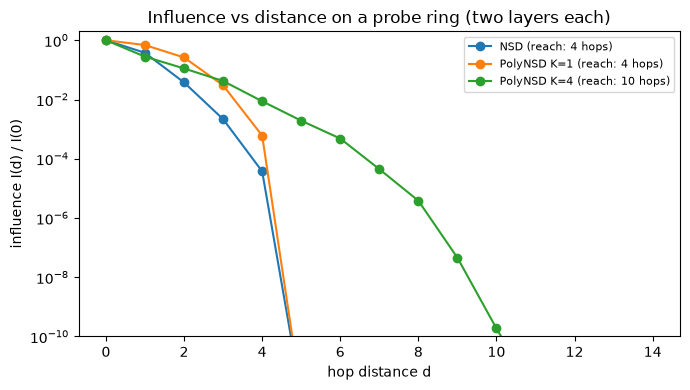

In [8]:
# =====================================================================
# Jacobian influence as a function of hop distance
# =====================================================================
def influence_by_distance(model, x, edge_index, graph, targets, max_hops=14):
    model.eval()
    totals = np.zeros(max_hops + 1)
    counts = np.zeros(max_hops + 1)
    for u in targets:
        x_in = x.clone().requires_grad_(True)
        model(x_in, edge_index)[u].abs().sum().backward()
        infl = x_in.grad.abs().sum(1).numpy()
        dist = nx.single_source_shortest_path_length(graph, int(u))
        for v, d_uv in dist.items():
            if d_uv <= max_hops:
                totals[d_uv] += infl[v]
                counts[d_uv] += 1
    mean = totals / np.maximum(counts, 1)
    return mean / mean[0]


# A long probe ring with features from the training distribution.
set_seed(1)
n_probe = 60
probe_graph = nx.cycle_graph(n_probe)
probe_edge_index = torch.tensor(list(probe_graph.edges())).t()
probe_edge_index = torch.cat([probe_edge_index, probe_edge_index.flip(0)], 1)
probe_x = torch.randn(n_probe, 4)
probe_x[:, 0] += 0.7 * (2 * torch.randint(0, 2, (n_probe,)).float() - 1)
targets = range(0, n_probe, 5)

hops = np.arange(15)
fig, ax = plt.subplots(figsize=(7, 4))
for name in ["NSD", "PolyNSD K=1", "PolyNSD K=4"]:
    curve = influence_by_distance(
        trained[name][0], probe_x, probe_edge_index, probe_graph, targets
    )
    reach = int(np.nonzero(curve > 0)[0].max())
    ax.semilogy(
        hops,
        np.maximum(curve, 1e-12),
        marker="o",
        label=f"{name} (reach: {reach} hops)",
    )
    print(f"{name:<12} last hop with non-zero influence: {reach}")
ax.set(
    xlabel="hop distance d",
    ylabel="influence I(d) / I(0)",
    ylim=(1e-10, 2),
    title="Influence vs distance on a probe ring (two layers each)",
)
ax.legend(fontsize=8)
plt.tight_layout()
plt.show()

Each curve drops to the plotted floor (exactly zero influence) at the edge of the model's receptive field, which is **layers × (K + 1)** hops: 4 for the first-order models and 10 for $K = 4$. The extra hop per layer comes from the degree normalization, which reads the restriction maps of neighbouring edges, so every layer also sees the degrees, and hence the features, of nodes one hop beyond its messages. The comparison is the point. With the same two layers, PolyNSD with $K = 4$ reaches several times further than the first-order models, and its influence decays gradually instead of being cut off. The paper measures the same quantity on large heterophilic benchmarks, comparing NSD and PolyNSD for each restriction-map family:

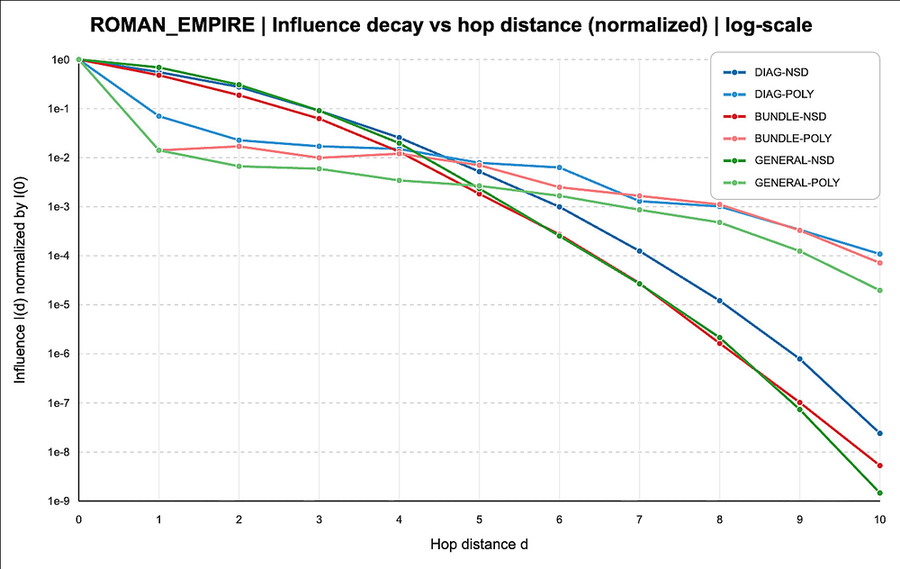

*Influence decay with hop distance on Roman-Empire (log scale, normalized by the influence at distance 0) for NSD and PolyNSD with diagonal, bundle, and general restriction maps. The PolyNSD curves decay much more slowly, i.e. distant nodes keep a measurable influence.*

<sub>Source: Borgi, Silvestri & Liò (2025), *Polynomial Neural Sheaf Diffusion: A Spectral Filtering Approach on Cellular Sheaves*, [arXiv:2512.00242](https://arxiv.org/abs/2512.00242), appendix. Reproduced for teaching with attribution (CC BY-NC-SA 4.0).</sub>

<a id="8-exercises"></a>
# 8. Configuration, Reproducibility, and Exercises

**Using it on real data.** PolyNSD is the `POLY_NSD` model type; the polynomial knobs are `--model.degree`, `--model.lambda-max`, and `--model.hp-alpha-init`:

```bash
sheaf run --preset texas_poly_nsd_general
sheaf run --preset chameleon_poly_nsd_diagonal --model.degree 6
python -m exp.het_run --preset dblp --model.type poly_het_nsd   # heterogeneous mirror
```

Record the degree $K$, $\lambda_{\max}$, the restriction-map family, the depth, and the seed. Degree and depth are different controls: depth adds nonlinearities and new restriction maps, while degree only widens each layer's spectral filter.

**Key takeaways**
* A degree-$K$ polynomial of the sheaf Laplacian is a $K$-hop local, learnable spectral filter, computed with $K$ message-passing steps and no eigendecomposition.
* Chebyshev polynomials on the rescaled spectrum keep the recurrence stable; softmax weights bound the response.
* A trained PolyNSD is inspectable: its frequency response, the spectrum of its learned sheaf, and its influence profile all come straight from the parameters.

### Hands-on Exercises
1. **Degree sweep.** Train $K \in \{1, 2, 4, 6, 8\}$ and plot test accuracy and time per epoch. Where does extra reach stop paying off?
2. **Homophily.** Rebuild the graph with $h = 0.85$. How do the learned responses change? Do you see the low-pass shape of a GCN?
3. **Spectral bound.** Set `lambda_max=1.0` (too small). Check the reconstructed spectrum: which eigenvalues now fall outside the Chebyshev range, and what happens to training?
4. **Restriction maps.** Repeat Section 7.1 with `PolyNSDVariant.ORTHOGONAL`. You will need to adapt `diagonal_sheaf_spectrum` to $d \times d$ blocks.